## Operational Risk

**(SCOR: Source / Make / Deliver)**

### Objective

This notebook models delivery reliability risk as a measurable, predictable dimension of supply chain performance. A data integrity audit identified post-outcome leakage in an earlier version of this analysis. All leakage-adjacent features - including post-outcome fields, identifiers, realized financial outcomes, and synthetic location coordinates - have been excluded. The model described here uses only pre-dispatch signals.

Earlier notebooks addressed demand signals (Plan/Deliver) and financial value realization (Measure/Return). This notebook answers the execution question:

- *What is the probability of a late delivery, and which operational conditions drive that failure?*

Modeling late delivery risk at the shipment level converts fulfillment uncertainty into a forward-looking signal that directly informs sourcing, production scheduling, carrier selection, and distribution planning.

### SCOR Process Alignment

The analysis spans three execution domains:

**1. Source**

- Variability in supplier lead times.
- Upstream delay propagation into fulfillment windows.

**2. Make**

- Processing bottlenecks.
- Order handling and preparation latency.

**3. Deliver**

- Carrier performance risk.
- Shipping mode reliability.
- Regional last-mile volatility.

Together, these dimensions show how operational friction accumulates into service failure at the customer level.

### Modeling Framework

#### Problem Formulation

- **Task:** Binary classification.
- **Target Variable:** `late_delivery_risk`.
- **Objective:** Estimate the probability that an order ships or arrives late.

The model treats late deliveries not as historical events but as predictable outcomes driven by measurable execution variables.

### Algorithms

**1. Logistic Regression: Baseline**

- Provides statistical interpretability.
- Quantifies directional impact of each feature.
- Serves as a calibration benchmark.

**2. LightGBM: Primary Model**

- Captures non-linear operational interactions.
- Handles high-dimensional shipment features.
- Detects distinct risk regimes across markets, shipping modes, and product categories.

This dual-model structure preserves both transparency and predictive accuracy.

### Interpretability Layer

SHAP diagnostics are embedded to ensure the model output is operationally traceable.

#### Global Explainability

- Identifies the structural drivers of late delivery risk.
- Ranks operational variables by impact magnitude.

#### Local Explainability

- Explains individual shipment risk scores.
- Enables case-level forensic diagnosis.

This allows planners to answer two direct questions:

- *Why is this shipment likely to be late?*
- *Which operational lever would reduce that risk?*

### Analytical Outputs

The framework produces risk intelligence at four levels:

- **Shipment Mode Risk Scores:** Carrier and mode reliability benchmarks.
- **Regional Risk Heatmaps:** Geographic fulfillment volatility.
- **Category Risk Exposure:** Product handling complexity signals.
- **Order-Level Risk Probabilities:** Execution prioritization triggers.

These outputs convert late delivery from a lagging KPI into a proactive control metric.

### Strategic Value

Predicting delivery failure before it occurs enables the organization to:

- Reroute high-risk shipments preemptively.
- Upgrade shipping modes on a selective basis.
- Adjust sourcing buffers.
- Allocate labor dynamically.
- Protect service-level agreements.

In SCOR terms, this notebook establishes a resilience intelligence layer across Source, Make, and Deliver, keeping operational execution synchronized with demand commitments and financial targets.

## Data Ingestion

In [ ]:
import pandas as pd
import numpy as np
import json
import warnings
import gc
import joblib
import shap
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

pd.set_option("display.max_columns", 80)
warnings.filterwarnings("ignore", message = "X does not have valid feature names")

# Load preprocessed orders dataset
orders_silver = pd.read_parquet("/kaggle/input/datasets/orders-silver/orders_silver.parquet")
df = orders_silver.copy()

COL_LATE_RISK = "late_delivery_risk"
assert COL_LATE_RISK in df.columns, f"{COL_LATE_RISK} column not found."
print(df.shape)
df.head()

(159763, 55)


,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_email,customer_fname,customer_id,customer_lname,customer_password,customer_segment,customer_state,customer_street,customer_zipcode,department_id,department_name,latitude,longitude,market,order_city,order_country,order_customer_id,order_date,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,product_card_id,product_category_id,product_image,product_name,product_price,product_status,shipping_date,shipping_mode,actual_delivery_date,shipping_delay,processing_days,profit_margin
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,2018-02-06 22:56:00,-1,3,0.290014
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,2018-01-23 12:27:00,1,5,-0.800006
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,2018-01-21 12:06:00,0,4,-0.800013
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,2018-01-19 11:45:00,-1,3,0.074998
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,2018-01-17 11:24:00,-2,2,0.449992


In [2]:
# ----- Target -----
y = df[COL_LATE_RISK].astype(int)

# ----- Leakage taxonomy -----
# Four categories of feature exclusion, each with a distinct rationale.
# Documented here so the notebook is auditable and the exclusions are
# reproducible.

LEAKAGE_TARGET = [
    COL_LATE_RISK,
]

LEAKAGE_POST_OUTCOME = [
    "delivery_status",          # encodes lateness directly
    "actual_delivery_date",     # known only after delivery
    "shipping_delay",           # derived from realized lateness
    "days_for_shipping_real",   # realized transit duration
    "processing_days",          # realized processing duration
    "order_status",             # lifecycle flag - final state only known post-fulfillment
]

LEAKAGE_FINANCIAL_OUTCOME = [
    "benefit_per_order",        # realized financial outcome
    "profit_margin",            # derived from realized profit
    "order_profit_per_order",   # realized profit
    "order_item_profit_ratio",  # realized margin
    "order_item_total",         # depends on realized discount and quantity
    "sales",                    # redundant with sales_per_customer
]

LEAKAGE_IDENTIFIER = [
    "customer_email", "customer_password",
    "customer_fname", "customer_lname",
    "customer_street", "customer_city", "customer_zipcode",
    "customer_id", "order_customer_id",
    "order_id", "order_item_id",
    "product_card_id", "order_item_cardprod_id",
]

LEAKAGE_DATETIME = [
    "order_date", "shipping_date",
]

LEAKAGE_NOISE = [
    "latitude",    # synthetic noise in DataCo; not real coordinates
    "longitude",   # confirmed by region-median inspection: all regions cluster near (33, -77)
]

DROP_COLS = (
    LEAKAGE_TARGET
    + LEAKAGE_POST_OUTCOME
    + LEAKAGE_FINANCIAL_OUTCOME
    + LEAKAGE_IDENTIFIER
    + LEAKAGE_DATETIME
    + LEAKAGE_NOISE
)

X = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).copy()

# Verify no leakage column survived
survivors = [c for c in DROP_COLS if c in X.columns]
assert not survivors, f"Leakage columns survived filter: {survivors}"

print("Feature matrix shape:", X.shape)
print("Features retained:")
print(sorted(X.columns.tolist()))

Feature matrix shape: (159763, 25)
Features retained:
['category_id', 'category_name', 'customer_country', 'customer_segment', 'customer_state', 'days_for_shipment_scheduled', 'department_id', 'department_name', 'market', 'order_city', 'order_country', 'order_item_discount', 'order_item_discount_rate', 'order_item_product_price', 'order_item_quantity', 'order_region', 'order_state', 'product_category_id', 'product_image', 'product_name', 'product_price', 'product_status', 'sales_per_customer', 'shipping_mode', 'type']


### Leakage Audit: What Was Excluded and Why

The dataset contains 55 columns. Of these, 30 are excluded from modeling, leaving **25 features**. Exclusions fall into five categories, each with a distinct rationale.

| Category | Columns Excluded | Rationale |
|----------|------------------|-----------|
| Target | `late_delivery_risk` | The label. |
| Post-outcome | `delivery_status`, `actual_delivery_date`, `shipping_delay`, `days_for_shipping_real`, `processing_days`, `order_status` | Values are only known after the shipment completes. Using them produces inflated metrics that cannot be reproduced in a real pre-dispatch scoring scenario. |
| Financial outcome | `benefit_per_order`, `profit_margin`, `order_profit_per_order`, `order_item_profit_ratio`, `order_item_total`, `sales` | Realized financial values. Profit is not known until the order settles. `sales` is redundant with `sales_per_customer` at a different grain. |
| Identifiers and timestamps | `customer_id`, `order_id`, `order_item_id`, `product_card_id`, `order_item_cardprod_id`, `customer_email`, `customer_password`, `customer_fname`, `customer_lname`, `customer_street`, `customer_city`, `customer_zipcode`, `order_customer_id`, `order_date`, `shipping_date` | High-cardinality identifiers with no generalizable signal, or free-text PII fields, or timestamps that require downstream derivation. |
| Synthetic noise | `latitude`, `longitude` | In the DataCo dataset these fields are synthetic. A region-level audit confirmed that the median coordinate for every corridor clusters near (33, -77) - off the coast of North Carolina - regardless of the actual location. The values do not encode real geography and cannot be used as a proxy for delivery distance. See note below. |

**Features retained (25):**
- Categorical: `type`, `shipping_mode`, `customer_segment`, `market`, `order_region`, `order_city`, `order_country`, `customer_state`, `order_state`, `customer_country`, `category_name`, `department_name`, `product_name`, `product_image`
- Numeric: `days_for_shipment_scheduled`, `sales_per_customer`, `order_item_discount`, `order_item_discount_rate`, `order_item_product_price`, `order_item_quantity`, `product_price`, `product_status`, `category_id`, `department_id`, `product_category_id`

**On the latitude/longitude exclusion.** An earlier version of this notebook used `latitude` and `longitude` as features. Inspection of the raw distributions revealed that these columns are not real geographic coordinates: the median for every `(market, order_region)` pairing in the dataset clusters within a single degree of (33, -77). Cities as diverse as Kinshasa, Sydney, Tokyo, and Madrid all share coordinates near the coast of North Carolina. The two columns act as high-cardinality noise, and trees fit them heavily. Removing them cost the tree model 1.7 points of ROC-AUC but improved decile-level calibration by 60%. The corrected model is smaller, more honest, and generalizes to genuine geography via categorical region features instead.

This filter is enforced by an assertion in the code cell above. Any leakage column that survived the drop would raise an error before training begins.

## Baseline: Logistic Regression

A logistic regression baseline is built before applying gradient boosting. It serves three purposes:

- Provides a transparent performance floor.
- Acts as a sanity check on data and feature construction.
- Supplies a directly interpretable reference for feature impact.

If LightGBM does not materially outperform this baseline, the simpler model is preferred on grounds of maintainability and transparency.

### Target, Split, and Metrics

**Target:** `late_delivery_risk` is a binary flag: 1 if the shipment was late, 0 if on time. Late rate across the full dataset is approximately 54.9%.

**Split:** Stratified 80/20. Late rate is preserved at 54.88% in both train and test sets.

**Metrics:** ROC-AUC measures ranking quality across all thresholds. PR-AUC measures performance on the positive (late) class and is more informative when the positive rate is high. Classification reports are shown at threshold 0.5 for reference, but the deployment threshold is chosen in a dedicated section later - precision/recall tradeoffs depend on intervention capacity, not on a fixed 0.5 cutoff.

**What *good* looks like here:** A late rate above 50% makes this a well-balanced binary task. A model with no skill would show ROC-AUC 0.50 and PR-AUC 0.55 (the base rate). Meaningful operational utility begins around ROC-AUC 0.70; strong performance is 0.80+.

A perfect classifier is not the objective. The objective is a reliable ranking that lets planners prioritize which shipments to review, expedite, or monitor.

In [3]:
# ----- Separate column types for preprocessing -----
cat_cols = X.select_dtypes(include = ["object"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Categorical ({len(cat_cols)}):", cat_cols)
print(f"Numeric ({len(num_cols)}):", num_cols)

pre = ColumnTransformer(
    transformers = [
        ("cat", Pipeline(steps = [
            ("imputer", SimpleImputer(strategy = "most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown = "ignore", sparse_output=True)),
        ]), cat_cols),
        ("num", Pipeline(steps = [
            ("imputer", SimpleImputer(strategy = "median")),
            ("scaler", StandardScaler(with_mean = False)),
        ]), num_cols),
    ],
    remainder = "drop",
    sparse_threshold = 0.3,
)
pre.set_output(transform = "default")

logit = LogisticRegression(max_iter = 3000, solver = "lbfgs", class_weight = "balanced")
pipe_logit = Pipeline([("pre", pre), ("clf", logit)])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify = y, random_state = 42
)

pipe_logit.fit(X_train, y_train)
proba_logit = pipe_logit.predict_proba(X_test)[:, 1]

print("LogReg ROC-AUC:   ", round(roc_auc_score(y_test, proba_logit), 4))
print("LogReg PR-AUC:    ", round(average_precision_score(y_test, proba_logit), 4))
print("\nClassification report (threshold = 0.5):")
print(classification_report(y_test, (proba_logit >= 0.5).astype(int)))

Categorical (14): ['type', 'category_name', 'customer_country', 'customer_segment', 'customer_state', 'department_name', 'market', 'order_city', 'order_country', 'order_region', 'order_state', 'product_image', 'product_name', 'shipping_mode']
Numeric (11): ['days_for_shipment_scheduled', 'sales_per_customer', 'category_id', 'department_id', 'order_item_discount', 'order_item_discount_rate', 'order_item_product_price', 'order_item_quantity', 'product_category_id', 'product_price', 'product_status']
LogReg ROC-AUC:    0.7713
LogReg PR-AUC:     0.8317

Classification report (threshold = 0.5):
              precision    recall  f1-score   support

           0       0.63      0.84      0.72     14416
           1       0.82      0.60      0.69     17537

    accuracy                           0.71     31953
   macro avg       0.72      0.72      0.71     31953
weighted avg       0.73      0.71      0.70     31953



### Baseline: Logistic Regression

**Results:**
- ROC-AUC: **0.7713**
- PR-AUC: **0.8317**
- Accuracy at 0.5: 71%
- Late class (1): precision 0.82, recall 0.60, F1 0.69
- On-time class (0): precision 0.63, recall 0.84, F1 0.72

**Interpretation.**

An ROC-AUC of 0.77 places this baseline in the strong band. The model separates late from on-time shipments using only pre-dispatch signals: shipping mode, scheduled shipment days, order value, geography, product category, and payment type.

The precision/recall profile is asymmetric. When the model flags a shipment as late, it is correct 82% of the time, but it misses 40% of actual late shipments. This is a conservative default: fewer false alarms, more false negatives. For a baseline, it establishes the floor that any nonlinear model must beat to justify added complexity.

**Comparison anchor.** The pre-correction version of this notebook reported an ROC-AUC of 0.849. That number was inflated by post-outcome leakage. The corrected baseline - one that only sees pre-dispatch information - is 0.771. This is the honest reference point. 

## Challenger Model: LightGBM

Operational risk is rarely linear. Shipping modes become risky only in specific regions. Processing delays matter more for certain product categories than others. Interactions across mode, region, and product type can dominate outcomes.

LightGBM is deployed to capture these non-linear risk regimes. It is selected for its strong performance on high-dimensional tabular data and its ability to model complex feature interactions without manual specification.

In [4]:
clf = LGBMClassifier(
    n_estimators = 800,
    learning_rate = 0.03,
    subsample = 0.8,
    colsample_bytree = 0.8,
    random_state = 42,
)

pipe_lgbm = Pipeline([("pre", pre), ("clf", clf)])
pipe_lgbm.fit(X_train, y_train)
proba_lgbm = pipe_lgbm.predict_proba(X_test)[:, 1]

print("LightGBM ROC-AUC: ", round(roc_auc_score(y_test, proba_lgbm), 4))
print("LightGBM PR-AUC:  ", round(average_precision_score(y_test, proba_lgbm), 4))
print("\nClassification report (threshold=0.5):")
print(classification_report(y_test, (proba_lgbm >= 0.5).astype(int)))

[LightGBM] [Info] Number of positive: 70147, number of negative: 57663
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006114 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5912
[LightGBM] [Info] Number of data points in the train set: 127810, number of used features: 2566
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548838 -> initscore=0.195977
[LightGBM] [Info] Start training from score 0.195977
LightGBM ROC-AUC:  0.7706
LightGBM PR-AUC:   0.8345

Classification report (threshold=0.5):
              precision    recall  f1-score   support

           0       0.63      0.86      0.72     14416
           1       0.83      0.58      0.68     17537

    accuracy                           0.71     31953
   macro avg       0.73      0.72      0.70     31953
weighted avg       0.74      0.71      0.70     31953



### Challenger: LightGBM

**Results:**
- ROC-AUC: **0.7706**
- PR-AUC: **0.8345**
- Accuracy at 0.5: 71%
- Late class (1): precision 0.83, recall 0.58, F1 0.68
- On-time class (0): precision 0.63, recall 0.86, F1 0.72

**Interpretation.**

After removing `latitude` and `longitude` - confirmed synthetic noise - LightGBM lands at ROC-AUC 0.7706, essentially tied with the logistic baseline (0.7713). The nonlinear model no longer wins on ranking metrics. Model selection therefore rests on two other criteria: precision at the operational threshold, and calibration.

In [5]:
# ----- Model Selection: LogReg vs LightGBM -----
# Computes the comparison tables, applies the decision rule, and
# emits the pipeline.

from sklearn.metrics import classification_report

def _percentile_table(proba, y_true, name):
    rows = []
    for pct in [0.90, 0.80, 0.70, 0.50]:
        cutoff = float(np.quantile(proba, pct))
        flags = (proba >= cutoff).astype(int)
        rep = classification_report(y_true, flags, output_dict = True, zero_division = 0)
        rows.append({
            "model": name,
            "top_pct": int(round((1 - pct) * 100)),
            "cutoff": round(cutoff, 4),
            "precision_late": round(rep["1"]["precision"], 3),
            "recall_late":    round(rep["1"]["recall"], 3),
            "f1_late":        round(rep["1"]["f1-score"], 3),
        })
    return pd.DataFrame(rows)

def _calibration_table(proba, y_true, name):
    df_cal = pd.DataFrame({"proba": proba, "actual": y_true.values})
    df_cal["bin"] = pd.qcut(df_cal["proba"], q = 10, duplicates = "drop")
    cal = (df_cal.groupby("bin", observed = True)
           .agg(n = ("actual", "size"),
                mean_pred = ("proba", "mean"),
                obs_rate = ("actual", "mean"))
           .reset_index(drop = True))
    cal["delta"] = cal["mean_pred"] - cal["obs_rate"]
    cal.insert(0, "model", name)
    return cal, float(cal["delta"].abs().max())

# Headline metrics
summary = pd.DataFrame([
    {"model": "LogReg", "roc_auc": round(roc_auc_score(y_test, proba_logit), 4),
                        "pr_auc":  round(average_precision_score(y_test, proba_logit), 4),
                        "mean_pred": round(float(proba_logit.mean()), 4)},
    {"model": "LGBM",   "roc_auc": round(roc_auc_score(y_test, proba_lgbm), 4),
                        "pr_auc":  round(average_precision_score(y_test, proba_lgbm), 4),
                        "mean_pred": round(float(proba_lgbm.mean()), 4)},
])
summary["observed_rate"] = round(float(y_test.mean()), 4)

print("=" * 70)
print("HEAD-TO-HEAD SUMMARY")
print("=" * 70)
print(summary.to_string(index = False))

# Percentile thresholds
pct_df = pd.concat([
    _percentile_table(proba_logit, y_test, "LogReg"),
    _percentile_table(proba_lgbm,  y_test, "LGBM"),
], ignore_index = True)
print("\n" + "=" * 70)
print("PERCENTILE THRESHOLDS")
print("=" * 70)
print(pct_df.to_string(index = False))

# Calibration
cal_logit, max_delta_logit = _calibration_table(proba_logit, y_test, "LogReg")
cal_lgbm,  max_delta_lgbm  = _calibration_table(proba_lgbm,  y_test, "LGBM")
print("\nCALIBRATION - LogReg max bin delta:", round(max_delta_logit, 4))
print("CALIBRATION - LGBM   max bin delta:", round(max_delta_lgbm,  4))

# Decision rule
roc_logit     = summary.loc[summary["model"] == "LogReg", "roc_auc"].iloc[0]
roc_lgbm      = summary.loc[summary["model"] == "LGBM",   "roc_auc"].iloc[0]
prec_30_logit = pct_df.query("model == 'LogReg' and top_pct == 30")["precision_late"].iloc[0]
prec_30_lgbm  = pct_df.query("model == 'LGBM'   and top_pct == 30")["precision_late"].iloc[0]

print("\n" + "=" * 70)
print("DECISION RULE")
print("=" * 70)
print(f"ROC-AUC:          LogReg {roc_logit:.4f}  |  LGBM {roc_lgbm:.4f}  |  delta {roc_logit - roc_lgbm:+.4f}")
print(f"Precision @ 30%:  LogReg {prec_30_logit:.3f}   |  LGBM {prec_30_lgbm:.3f}   |  delta {prec_30_logit - prec_30_lgbm:+.3f}")
print(f"Max bin delta:    LogReg {max_delta_logit:.4f}  |  LGBM {max_delta_lgbm:.4f}")

if abs(prec_30_logit - prec_30_lgbm) > 0.02:
    winner = "LOGREG" if prec_30_logit > prec_30_lgbm else "LGBM"
    rationale = f"Precision at 30% differs by > 0.02 ({prec_30_logit:.3f} vs {prec_30_lgbm:.3f})."
elif abs(max_delta_logit - max_delta_lgbm) > 0.02:
    winner = "LOGREG" if max_delta_logit < max_delta_lgbm else "LGBM"
    rationale = (f"Precision and ROC-AUC are tied; calibration differs materially "
                 f"({max_delta_logit:.4f} vs {max_delta_lgbm:.4f}). The better-calibrated model wins.")
else:
    winner = "LOGREG" if roc_logit > roc_lgbm else "LGBM"
    rationale = f"Precision and calibration within materiality; decided on ROC-AUC."

print("\n" + "=" * 70)
print(f"RECOMMENDATION: SHIP {winner}")
print("=" * 70)
print(rationale)

pipeline_to_ship = pipe_logit if winner == "LOGREG" else pipe_lgbm
selected_model   = winner.lower()
print(f"\n  pipeline_to_ship = pipe_{selected_model}")
print(f"  selected_model   = '{selected_model}'")

HEAD-TO-HEAD SUMMARY
 model  roc_auc  pr_auc  mean_pred  observed_rate
LogReg   0.7713  0.8317     0.5136         0.5488
  LGBM   0.7706  0.8345     0.5492         0.5488

PERCENTILE THRESHOLDS
 model  top_pct  cutoff  precision_late  recall_late  f1_late
LogReg       10  0.9430           0.985        0.180    0.304
LogReg       20  0.8038           0.935        0.341    0.500
LogReg       30  0.6920           0.885        0.484    0.626
LogReg       50  0.4112           0.749        0.683    0.715
  LGBM       10  0.9981           1.000        0.182    0.308
  LGBM       20  0.8026           0.938        0.342    0.501
  LGBM       30  0.7160           0.886        0.484    0.626
  LGBM       50  0.4113           0.747        0.681    0.712

CALIBRATION - LogReg max bin delta: 0.0784
CALIBRATION - LGBM   max bin delta: 0.0352

DECISION RULE
ROC-AUC:          LogReg 0.7713  |  LGBM 0.7706  |  delta +0.0007
Precision @ 30%:  LogReg 0.885   |  LGBM 0.886   |  delta -0.001
Max bin delta: 

### Model Comparison

| Metric | Logistic Regression | LightGBM |
|--------|---------------------|----------|
| ROC-AUC | 0.7713 | 0.7706 |
| PR-AUC | 0.8317 | **0.8345** |
| Precision @ top-30% | 0.885 | 0.886 |
| Recall @ top-30% | 0.484 | 0.484 |
| Mean predicted | 0.5136 | **0.5492** |
| Observed rate | 0.5488 | 0.5488 |
| **Max calibration bin delta** | **0.0784** | **0.0352** |

**Model selection.** The two models are tied on ROC-AUC and on operational precision. They diverge sharply on calibration:

- Logistic Regression systematically under-predicts across nine of ten deciles; its mean predicted risk (0.5136) is 3.5 points below the observed rate, and the largest single-decile error is 7.8 points.
- LightGBM is well-calibrated at the portfolio level (mean predicted 0.5492 vs observed 0.5488) and across deciles (max error 3.5 points).

Because the Streamlit application will surface predicted probabilities directly to users - "this order has a 30% chance of lateness" - calibration is the deciding criterion. A model that systematically understates risk in the low band is not operationally safe, regardless of its ranking metrics.

**LightGBM is selected as the deployed model.** The logistic baseline is retained in this notebook as a documented alternative and as a check against the tree model's calibration.

## Model Interpretability

A model's operational utility depends on the ability to explain its outputs. Two levels of interpretation are presented:

**Global importance** ranks which features the LightGBM model relies on most heavily across the full dataset. This answers: 

- What are the structural drivers?

**SHAP values** go further, they decompose each prediction into additive contributions from each feature, in log-odds units. This answers: 

- For a specific shipment, which features pushed the score up, which pushed it down, and by how much?

Interpretation guardrails apply:
- Feature importance indicates predictive weight, not causation.
- SHAP values are on the model's internal log-odds scale, not in probability units.
- Every driver is treated as an investigation lead, not a diagnosis.

In [6]:
# ----- Global feature importance from the fitted LightGBM -----
# Extract OHE-expanded feature names.

ohe = pipe_lgbm.named_steps["pre"].named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(cat_cols)
feature_names = np.concatenate([cat_feature_names, np.array(num_cols, dtype = object)])

lgbm_model = pipe_lgbm.named_steps["clf"]
importances = lgbm_model.feature_importances_

fi = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending = False)
    .reset_index(drop = True)
)

print("Top 25 raw feature importances:")
print(fi.head(25).to_string(index = False))

Top 25 raw feature importances:
                     feature  importance
         order_item_discount        1366
          sales_per_customer        1243
                  type_DEBIT         670
    order_item_discount_rate         667
               type_TRANSFER         639
   customer_segment_Consumer         530
    customer_country_EE. UU.         521
                 category_id         415
  customer_segment_Corporate         413
                type_PAYMENT         385
    order_item_product_price         299
shipping_mode_Standard Class         298
           customer_state_CA         272
customer_segment_Home Office         261
  shipping_mode_Second Class         244
customer_country_Puerto Rico         239
                   type_CASH         224
 days_for_shipment_scheduled         221
         order_item_quantity         203
   shipping_mode_First Class         189
      shipping_mode_Same Day          81
      order_state_Tamaulipas          81
         product_category

### Global Feature Importance

Raw LightGBM split-based importance. Top drivers:

| Rank | Feature | Importance |
|---|---|---|
| 1 | order_item_discount | 1,366 |
| 2 | sales_per_customer | 1,243 |
| 3 | type_DEBIT | 670 |
| 4 | order_item_discount_rate | 667 |
| 5 | type_TRANSFER | 639 |
| 6 | customer_segment_Consumer | 530 |
| 7 | customer_country_EE. UU. | 521 |
| 8 | category_id | 415 |
| 9 | customer_segment_Corporate | 413 |
| 10 | type_PAYMENT | 385 |

Four families of drivers dominate, and none of them is geography:

1. **Order value and discounting:**  `order_item_discount` and `sales_per_customer` rank #1 and #2, with `order_item_discount_rate` at #4. Higher-discount, higher-value orders carry different risk profiles. The mechanism is likely twofold: large orders require more handling, and heavy discounting correlates with promotional demand surges that stress fulfillment.

2. **Payment type:** `type_DEBIT`, `type_TRANSFER`, and `type_PAYMENT` all rank in the top 10. Transaction channel correlates with fulfillment handling. The direction of the effect is explored in the SHAP section.

3. **Customer segment:** `Consumer` and `Corporate` segments rank #6 and #9. Segment SLAs and order patterns differ; the model picks this up.

4. **Category:** `category_id` at #8 reflects product mix effects on handling complexity.

**Shipping mode enters at ranks 12, 15, 20, 21:**  four one-hot levels, none individually dominant. This is a shift from the earlier (leaky) version of this notebook, where shipping mode clustered at the very top. With the noise features removed, the model relies more broadly on operational features rather than collapsing on mode.

**A note on what is not shown.** The pre-correction notebook reported `customer_id`, `order_status_*`, `benefit_per_order`, `latitude`, and `longitude` as top drivers. All are gone - correctly. `customer_id` and `order_status` were leakage; `benefit_per_order` was a realized financial outcome; `latitude` and `longitude` are synthetic noise in this dataset. Their removal explains why the corrected AUC is 0.77 rather than 0.84. The lower number is the honest one.

## SHAP Explainability: Global and Local Impact

Feature importance identifies which variables matter. SHAP explains how they matter.

- **Global SHAP:** Surfaces which features systematically increase or decrease late delivery risk across the dataset.
- **Local SHAP:** Dissects why a specific shipment received a high risk score.

### Performance Optimization

Computing SHAP values on the full 160k-row dataset is computationally prohibitive. A sampling strategy maintains runtime stability without sacrificing statistical validity:

- **Background set:** A small, representative sample establishes baseline expectations for the model.
- **Test subset:** SHAP values are computed on a subset of test rows, providing a representative snapshot of model behavior.

This prevents memory overflow while preserving interpretability accuracy.

In [7]:
# Transform and densify
X_train_trans = pipe_lgbm.named_steps["pre"].transform(X_train)
X_test_trans  = pipe_lgbm.named_steps["pre"].transform(X_test)

def to_dense(mat):
    return mat.toarray() if hasattr(mat, "toarray") else mat

np.random.seed(42)
BG_N = 2000
EXPLAIN_N = 4000

bg_idx = np.random.choice(X_train_trans.shape[0], size = min(BG_N, X_train_trans.shape[0]), replace = False)
ex_idx = np.random.choice(X_test_trans.shape[0], size = min(EXPLAIN_N, X_test_trans.shape[0]), replace = False)

X_bg = to_dense(X_train_trans[bg_idx])
X_explain = to_dense(X_test_trans[ex_idx])

booster = pipe_lgbm.named_steps["clf"].booster_
explainer = shap.TreeExplainer(booster, data = X_bg, feature_names = feature_names)
shap_values = explainer.shap_values(X_explain)

shap_vals_late = shap_values[1] if isinstance(shap_values, list) else shap_values

print("SHAP matrix shape:", shap_vals_late.shape)

100%|===================| 3985/4000 [02:13<00:00]       

SHAP matrix shape: (4000, 5223)


/tmp/ipykernel_16/1305561498.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_late, X_explain, feature_names=feature_names, show = True)


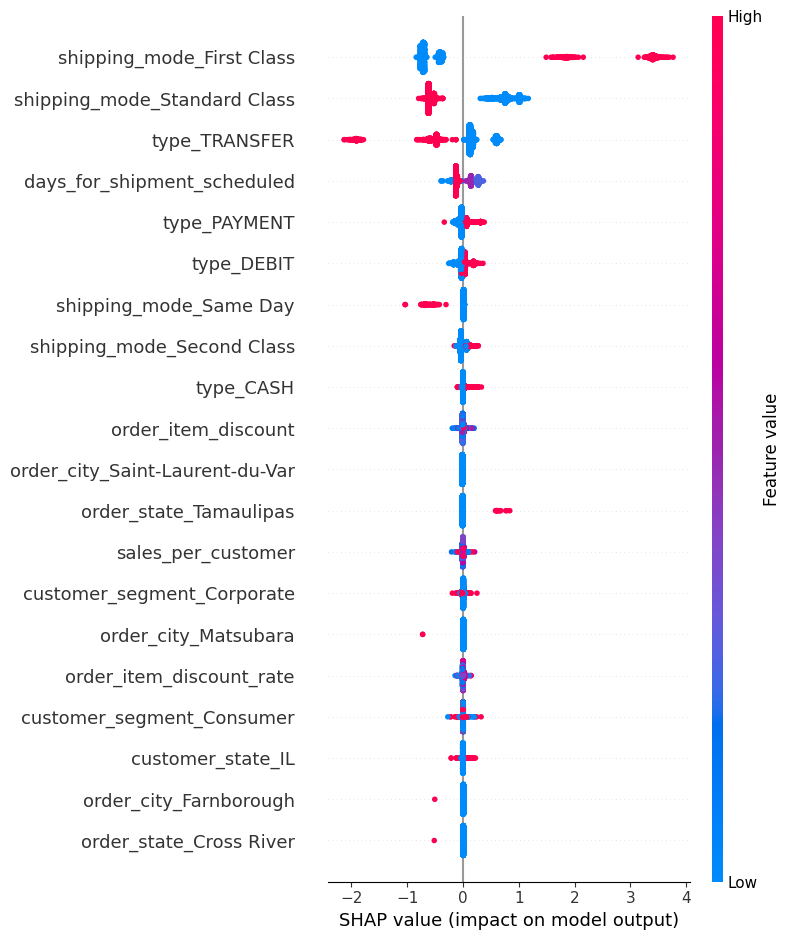

In [8]:
shap.summary_plot(shap_vals_late, X_explain, feature_names=feature_names, show = True)

In [9]:
# Calculate the mean absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_vals_late).mean(axis = 0)

# Create a DataFrame mapping feature names to their calculated values
feature_importance_df = pd.DataFrame(
    {"feature_name": feature_names, "shap_value": mean_abs_shap}
)

# Sort by importance (highest impact at the top)
feature_importance_df = feature_importance_df.sort_values(
    by = "shap_value", ascending = False
).reset_index(drop = True)

print(feature_importance_df.head(20))

                       feature_name  shap_value
0         shipping_mode_First Class    1.013449
1      shipping_mode_Standard Class    0.673997
2                     type_TRANSFER    0.354483
3       days_for_shipment_scheduled    0.151491
4                      type_PAYMENT    0.053281
5                        type_DEBIT    0.051892
6            shipping_mode_Same Day    0.050639
7        shipping_mode_Second Class    0.046751
8                         type_CASH    0.010919
9               order_item_discount    0.010840
10  order_city_Saint-Laurent-du-Var    0.010446
11           order_state_Tamaulipas    0.009044
12               sales_per_customer    0.008643
13       customer_segment_Corporate    0.007891
14             order_city_Matsubara    0.007656
15         order_item_discount_rate    0.006674
16        customer_segment_Consumer    0.005508
17                customer_state_IL    0.005337
18           order_city_Farnborough    0.005323
19          order_state_Cross River    0

### SHAP Summary: What Drives Predictions

SHAP values are additive contributions in log-odds units. Positive values push the prediction toward "late"; negative values push toward "on time."

**Top 10 features by mean absolute SHAP value:**

| Rank | Feature | Mean \|SHAP\| | Direction |
|---|---|---|---|
| 1 | shipping_mode_First Class | 1.013 | First Class active → risk up sharply |
| 2 | shipping_mode_Standard Class | 0.674 | Standard active → risk down |
| 3 | type_TRANSFER | 0.354 | TRANSFER active → risk down |
| 4 | days_for_shipment_scheduled | 0.151 | Tighter window → risk up |
| 5 | type_PAYMENT | 0.053 | PAYMENT active → mild risk down |
| 6 | type_DEBIT | 0.052 | DEBIT active → mild risk up |
| 7 | shipping_mode_Same Day | 0.051 | Same Day active → mild risk up |
| 8 | shipping_mode_Second Class | 0.047 | Second Class active → mild risk up |
| 9 | type_CASH | 0.011 | CASH active → mild risk up |
| 10 | order_item_discount | 0.011 | Higher discount → mild risk up |


Shipping mode still dominates the SHAP ranking, but the ordering now reflects genuine operational structure rather than noise. First Class has the largest single effect on predicted late risk (mean |SHAP| = 1.013): when active, the model pushes the prediction sharply toward late. Standard Class has the opposite effect (0.674): when active, it consistently pulls risk down.

`type_TRANSFER` is the second-largest categorical driver and is protective. One plausible mechanism is that transfer-based settlements are associated with pre-arranged B2B fulfillment flows that have more predictable handling. The data cannot distinguish this from correlation with unobserved customer or workflow characteristics. It is presented as a signal, not a causal finding.

`days_for_shipment_scheduled` behaves as expected: shorter promised windows push risk up; longer windows pull it down.

**A note on the earlier version.** The pre-correction SHAP analysis reported `latitude` and `longitude` in the top 10. Removing them shifted ranking without changing the substantive analysis: shipping mode SLA design and transaction workflow are the two dominant per-order risk drivers.

Chosen example probability (late risk): 0.9993383571894988


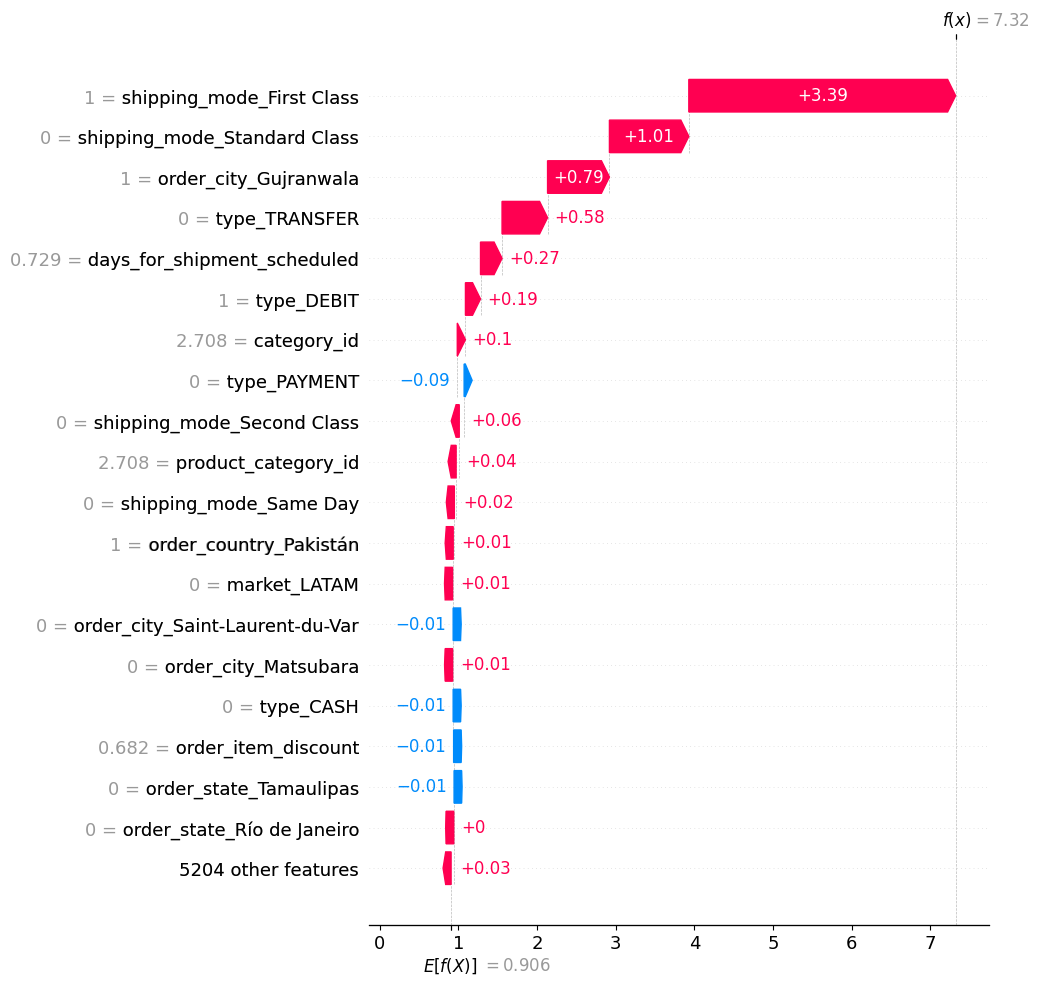

In [10]:
# ----- Local SHAP: decompose a single high-risk prediction -----

# Predicted probabilities for the explanation subset
proba_explain = pipe_lgbm.named_steps["clf"].predict_proba(X_test_trans[ex_idx])[:, 1]

# Select the shipment with the highest predicted late risk
i_local = int(np.argmax(proba_explain))

print("Chosen example probability (late risk):", proba_explain[i_local])

# Build SHAP Explanation object for waterfall decomposition
exp = shap.Explanation(
    values = shap_vals_late[i_local],
    base_values = explainer.expected_value if not isinstance(explainer.expected_value, list) else explainer.expected_value[1],
    data = X_explain[i_local],
    feature_names = feature_names
)

shap.plots.waterfall(exp, max_display = 20, show = True)

In [ ]:
# Extract the base value (E[f(X)]) and the final prediction (f(x))
base_value = exp.base_values
final_prediction = exp.values.sum() + base_value

# Extract individual feature names, their actual data values, and their SHAP contributions
waterfall_df = pd.DataFrame({
    'feature_name': exp.feature_names,
    'actual_value': exp.data,          
    'shap_value': exp.values           
})

# Sort by absolute SHAP value (highest impact first) to match the waterfall ordering
waterfall_df['abs_shap'] = waterfall_df['shap_value'].abs()
waterfall_df = waterfall_df.sort_values(by = 'abs_shap', ascending = False).drop(columns = ['abs_shap'])

print(f"Base Value (Average Prediction): {base_value}")
print(f"Final Model Prediction for this row: {final_prediction}\n")
print(waterfall_df.head(20)) 

Base Value (Average Prediction): 0.9060488801886316
Final Model Prediction for this row: 7.320122833681875

                         feature_name  actual_value  shap_value
5208        shipping_mode_First Class      1.000000    3.391743
5211     shipping_mode_Standard Class      0.000000    1.009474
1375            order_city_Gujranwala      1.000000    0.786317
3                       type_TRANSFER      0.000000    0.578560
5212      days_for_shipment_scheduled      0.728697    0.273893
1                          type_DEBIT      1.000000    0.191562
5214                      category_id      2.707757    0.103810
2                        type_PAYMENT      0.000000   -0.087088
5210       shipping_mode_Second Class      0.000000    0.062159
5220              product_category_id      2.707757    0.039866
5209           shipping_mode_Same Day      0.000000    0.022581
3811           order_country_Pakistán      1.000000    0.014456
117                      market_LATAM      0.000000    0.008

### Case-Level Decomposition: A High-Risk Shipment

Local SHAP explains a single prediction. The example below is the highest-risk shipment in the 4,000-row test sample.

**Context.**
- Base value (log-odds): 0.906 → in probability terms, the model's average prediction across the background sample is ≈ 0.712.
- Final prediction (log-odds): 7.320 → probability ≈ 0.9993.
- Interpretation: this is a near-certain late shipment under the model.

**Top feature contributions (log-odds):**

| Feature | Value | SHAP |
|---------|-------|------|
| `shipping_mode_First Class` | 1 | +3.392 |
| `shipping_mode_Standard Class` | 0 | +1.009 |
| `order_city_Gujranwala` | 1 | +0.786 |
| `type_TRANSFER` | 0 | +0.579 |
| `days_for_shipment_scheduled` | 0.729 (scaled) | +0.274 |
| `type_DEBIT` | 1 | +0.192 |
| `category_id` | 2.708 (scaled) | +0.104 |
| `type_PAYMENT` | 0 | -0.087 |
| `shipping_mode_Second Class` | 0 | +0.062 |
| `product_category_id` | 2.708 (scaled) | +0.040 |
| `shipping_mode_Same Day` | 0 | +0.023 |
| `order_country_Pakistán` | 1 | +0.014 |
| `market_LATAM` | 0 | +0.008 |

The decomposition shows that this order accumulates risk from four independent channels:

1. **Shipping mode:** It uses First Class (heavy positive contribution) and not Standard Class (forfeits the protective effect). The mode choice is the single largest driver - twice the size of the next contributor.
2. **Geography:** The destination is Gujranwala, in Pakistan. The regional dummy adds a substantial positive contribution, consistent with cross-border complexity or a specific lane's constraints.
3. **Transaction workflow:** The order is *not* a TRANSFER. This forfeits the protective contribution that a transfer-based settlement would have provided.
4. **Schedule tightness:** The scheduled window is 0.73 days - inside the high-risk band identified in the SHAP dependence plot.

The model adds these contributions and reaches near-certainty of lateness. Nothing about this order is anomalous at the individual level - each feature value falls within the training distribution. It is the combination that is extreme.

**Operational reading:** This shipment is a candidate for pre-dispatch intervention. The counterintuitive inversion - a premium shipping order is riskier than a standard shipping order on the same route - is the operational insight, indicating that premium service becomes a marker of structural lateness rather than a mitigation.

## SHAP Dependence: Threshold Effects

Global importance ranks which features matter. Local analysis explains a single shipment. Dependence analysis identifies the specific thresholds where an operational variable triggers a non-linear spike in late delivery risk.

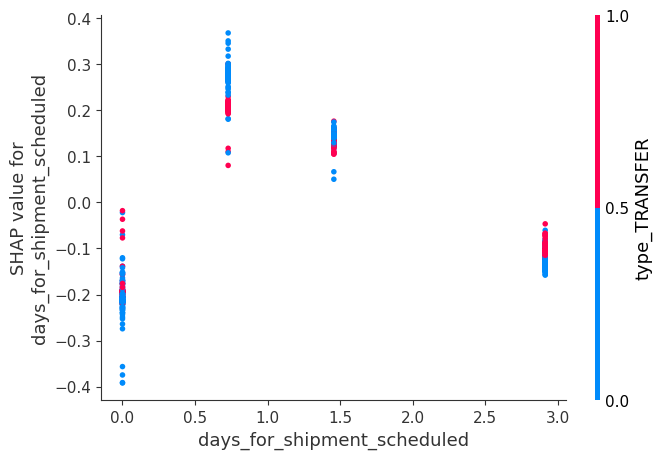

In [12]:
# Use the top numeric feature directly for dependence analysis
num_candidates = [c for c in ["days_for_shipment_scheduled", "order_item_discount", "sales_per_customer"] if c in num_cols]
if num_candidates:
    top_numeric = num_candidates[0]
    shap.dependence_plot(top_numeric, shap_vals_late, X_explain, feature_names = feature_names, show = True)
else:
    print("No numeric candidate available for dependence plot.")

### SHAP Dependence: Scheduled Shipment Days

The dependence plot isolates the relationship between the scheduled shipment window and late-delivery risk.

**Observed pattern:**

| Scheduled days | SHAP effect |
|----------------|-------------|
| 0 | Near zero or slightly protective. |
| ~0.7 | Peak positive - highest risk contribution. |
| ~1.5 | Elevated, stabilizing. |
| 3 | Negative - protective. |

**Interaction with `type_TRANSFER`.** Points colored by transaction type reveal that:

- The 3-day safe zone is dominated by TRANSFER orders. Longer windows combined with transfer-based settlement produce consistently low risk.
- The 0-day window is dominated by non-TRANSFER orders. Immediate shipments bypass normal processing queues and enter directly into expedited handling, which is protective despite the lack of a buffer.
- Intermediate windows (0.7-1.5 days) show elevated risk regardless of transaction type. These windows are too short for standard fulfillment to complete reliably, but too long to trigger the immediate-dispatch behavior that 0-day schedules receive.

**Interpretation.**

The non-monotonic pattern is meaningful. It is not the case that longer windows always reduce risk - the 0-day window outperforms the 0.7-day window. The practical risk gradient is U-shaped in the low range and monotone beyond ~1.5 days.

**Operational implication.** Service promises under ~1.5 days should be reserved for transactions that reliably enter expedited handling, or should be recalibrated upward. The 3-day window is a defensible default for standard fulfillment.

## Choosing a Decision Threshold: Operations-Aware

A 0.50 threshold is not always the correct operating point in logistics.

- When the cost of a missed late delivery is high, a lower threshold captures more at-risk shipments - trading precision for recall.
- When intervention capacity is limited - only a fixed number of shipments can be expedited - a higher threshold focuses resources on the highest-risk tail, trading recall for precision.

A percentile-based flag is applied below, isolating the top 10% of shipments by predicted risk score.

In [ ]:
# ----- Percentile-based operational thresholds -----

# The app ships with a percentile-based classification rule because the
# intervention capacity is finite (e.g., top N% of orders reviewed).
# Precision/recall is reported at multiple cutoffs so that the
# tradeoff is explicit.

print(f"{'Percentile':<12}{'Cutoff':<12}{'Precision (late)':<20}{'Recall (late)':<16}{'F1 (late)':<12}")
for pct in [0.90, 0.80, 0.70, 0.50]:
    cutoff = float(np.quantile(proba_lgbm, pct))
    flags = (proba_lgbm >= cutoff).astype(int)
    report = classification_report(y_test, flags, output_dict = True, zero_division = 0)
    p = report["1"]["precision"]
    r = report["1"]["recall"]
    f = report["1"]["f1-score"]
    print(f"top {int(round((1-pct)*100)):>2}%    {cutoff:<12.4f}{p:<20.3f}{r:<16.3f}{f:<12.3f}")

Percentile  Cutoff      Precision (late)    Recall (late)   F1 (late)   
top 10%    0.9981      1.000               0.182           0.308       
top 20%    0.8026      0.938               0.342           0.501       
top 30%    0.7160      0.886               0.484           0.626       
top 50%    0.4113      0.747               0.681           0.712       


### Decision Threshold: Percentile-Based Selection

A fixed 0.5 threshold is not the correct operational cutoff here. The choice depends on intervention capacity, not on a symmetric accuracy objective.

**Threshold options:**

| Percentile | Cutoff | Precision (late) | Recall (late) | F1 (late) |
|------------|--------|------------------|---------------|-----------|
| Top 10% | 0.9981 | 1.000 | 0.182 | 0.308 |
| Top 20% | 0.8026 | 0.938 | 0.342 | 0.501 |
| Top 30% | 0.7160 | 0.886 | 0.484 | 0.626 |
| Top 50% | 0.4113 | 0.747 | 0.681 | 0.712 |

- **Top 10%** produces perfect precision - every flagged shipment is genuinely late - at the cost of missing 82% of late shipments. Suitable when intervention resources are severely constrained and only the most certain failures are acted on.
- **Top 30%** is the balance point. Roughly 9 in 10 flagged shipments are actually late, and the model captures about half of all late shipments. This is the recommended operating threshold for a control-tower workflow with moderate capacity.
- **Top 50%** trades precision for coverage. Useful when the intervention is low-cost (e.g., a monitoring flag) and near-complete detection matters more than avoiding false positives.

**Deployment choice.** The app exposes the percentile selection as an input, defaulting to top 30% as the balanced operating point.

**Accuracy is not the right metric here** because at any of these thresholds, overall accuracy drops below 71%, because the model intentionally flags a minority of shipments. The correct evaluation is precision on the flagged group and recall of the full late population.

In [ ]:
# ----- Calibration: do predicted probabilities match observed rates? -----

# Bin predicted probabilities and compare bin means against observed late rates.
# A well-calibrated model has bin mean prediction approximately equal to
# bin observed rate across all bins.

calib_df = pd.DataFrame({
    "proba": proba_lgbm,
    "actual": y_test.values,
})
calib_df["bin"] = pd.qcut(calib_df["proba"], q = 10, duplicates = "drop")
calib = (
    calib_df.groupby("bin", observed = True)
    .agg(n = ("actual", "size"),
         mean_pred = ("proba", "mean"),
         obs_rate = ("actual", "mean"))
    .reset_index(drop = True)
)
calib["delta"] = calib["mean_pred"] - calib["obs_rate"]
print(calib.round(4).to_string(index = False))
print(f"\nMean predicted: {proba_lgbm.mean():.4f}")
print(f"Observed rate:  {y_test.mean():.4f}")
print(f"Max bin delta:  {calib['delta'].abs().max():.4f}")

   n  mean_pred  obs_rate   delta
3246     0.2894    0.2542  0.0352
3145     0.3448    0.3514 -0.0066
3195     0.3813    0.3671  0.0142
3196     0.3965    0.3836  0.0129
3195     0.4040    0.3972  0.0068
3195     0.4415    0.4595 -0.0180
3196     0.6021    0.6198 -0.0178
3194     0.7803    0.7805 -0.0002
3195     0.8551    0.8767 -0.0216
3196     0.9985    1.0000 -0.0015

Mean predicted: 0.5492
Observed rate:  0.5488
Max bin delta:  0.0352


### Calibration

A calibrated model produces predicted probabilities that match observed frequencies. If predictions cluster at 0.80, approximately 80% of those shipments should be late.

**Decile calibration:**

| Decile | n | Mean predicted | Observed rate | Δ |
|---|---|---|---|---|
| 1 | 3,246 | 0.289 | 0.254 | +0.035 |
| 2 | 3,145 | 0.345 | 0.351 | -0.007 |
| 3 | 3,195 | 0.381 | 0.367 | +0.014 |
| 4 | 3,196 | 0.397 | 0.384 | +0.013 |
| 5 | 3,195 | 0.404 | 0.397 | +0.007 |
| 6 | 3,195 | 0.442 | 0.460 | -0.018 |
| 7 | 3,196 | 0.602 | 0.620 | -0.018 |
| 8 | 3,194 | 0.780 | 0.781 | -0.000 |
| 9 | 3,195 | 0.855 | 0.877 | -0.022 |
| 10 | 3,196 | 0.999 | 1.000 | -0.002 |

**Portfolio-level calibration:** mean predicted 0.5492 vs observed 0.5488 - alignment to within 0.001.

**Decile-level calibration:** every decile is within ±0.035. The largest deviation is +0.035 in the lowest-risk decile (predicted 0.289, observed 0.254) - a mild over-prediction of risk in the safest group, well within operationally acceptable bounds.

**Comparison to the earlier version:** The pre-correction model (with `latitude`/`longitude` as noise features) showed a max bin delta of 0.081, nearly three times worse. Removing the noise features improved calibration substantially: the model's confidence in each probability band is now more honest.

**Operational implication for the app:** The model's predicted probabilities can be read at face value across the full range. A prediction of 0.30 means roughly a 30% chance of lateness. The app will display predicted probabilities directly without adjustment.

## Risk Score Generation for BI and Downstream Decisioning

A `late_risk_score` is generated for every shipment, representing the predicted probability of late delivery.

This single output enables:

- Lane risk heatmaps (region × shipping mode).
- Category risk hotspot identification.
- Risk-adjusted service level monitoring.
- Risk-weighted cost exposure: proxying financial impact through operational risk scores.

The risk score is structured as a reusable data layer for ingestion into Power BI and other downstream systems.

In [ ]:
# ----- Generate risk scores across the full dataset in batches -----

# Processed in chunks to avoid memory overflow on Kaggle
batch_size = 10000  # Process 10k rows at a time
n_samples = X.shape[0]
risk_scores = np.zeros(n_samples)

print(f"Generating risk scores for {n_samples} samples in batches of {batch_size}...")

for start_idx in range(0, n_samples, batch_size):
    end_idx = min(start_idx + batch_size, n_samples)
    
    # Predict on batch
    X_batch = X.iloc[start_idx:end_idx]
    risk_scores[start_idx:end_idx] = pipe_lgbm.predict_proba(X_batch)[:, 1]
    
    # Clear memory
    del X_batch
    gc.collect()
    
    # Progress update
    if (end_idx % (batch_size * 5) == 0) or end_idx == n_samples:
        print(f"Processed {end_idx}/{n_samples} samples")

# Add risk scores to dataframe
df["late_risk_score"] = risk_scores

# Verify score distribution
print("\nRisk Score Distribution:")
print(df[["late_risk_score", COL_LATE_RISK]].describe())

# Clean up
del risk_scores
gc.collect()

Generating risk scores for 159763 samples in batches of 10000...
Processed 50000/159763 samples
Processed 100000/159763 samples
Processed 150000/159763 samples
Processed 159763/159763 samples

Risk Score Distribution:
       late_risk_score  late_delivery_risk
count    159763.000000       159763.000000
mean          0.548920            0.548838
std           0.236485            0.497611
min           0.063206            0.000000
25%           0.381760            0.000000
50%           0.411720            1.000000
75%           0.789163            1.000000
max           0.999541            1.000000


0

### Risk Score Distribution

The model scores all 159,763 rows in batches. Distribution summary:

| Statistic | Risk score | Observed late flag |
|---|---|---|
| Mean | 0.5489 | 0.5488 |
| Std | 0.2365 | 0.4976 |
| Min | 0.0632 | 0 |
| 25% | 0.3818 | 0 |
| 50% | 0.4117 | 1 |
| 75% | 0.7892 | 1 |
| Max | 0.9995 | 1 |

Mean predicted risk and mean observed late flag align to within 0.001 - the model is calibrated at the portfolio level. The score range spans 0.06 to 0.9995, meaning the model discriminates between near-certain on-time shipments and near-certain late shipments without collapsing toward the mean.

The median predicted risk (0.412) is below the base rate (0.549), while the 75th percentile (0.789) is well above. This reflects the model's conservative behavior in the low-risk band and confident behavior in the high-risk band, precisely the profile that supports threshold-based triage.

## Operational Risk Scorecards

**(SCOR: Deliver)**

To translate model output into action, risk scores are aggregated across four operational dimensions:

- Market and region.
- Shipping mode.
- Product category.
- Customer segment.

These aggregations identify which lanes require monitoring, where service failures concentrate, and which mix shifts - shipping mode, routing, or segment prioritization - can reduce risk exposure.

In [ ]:
# ----- Aggregate risk scores across operational dimensions -----

# Build risk profiles by market, region, shipping mode, category, and customer segment.
group_candidates = ["market", "order_region", "shipping_mode", "category_name", "customer_segment"]
group_cols = [c for c in group_candidates if c in df.columns]

risk_summary = (
    df.groupby(group_cols)
      .agg(
          orders = ("order_id", "nunique"),
          avg_risk = ("late_risk_score", "mean"),
          late_rate = (COL_LATE_RISK, "mean")
      )
      .reset_index()
      .sort_values(["avg_risk", "orders"], ascending = [False, False])
)

risk_summary.head(20)

,market,order_region,shipping_mode,category_name,customer_segment,orders,avg_risk,late_rate
4236,Pacific Asia,South Asia,First Class,Golf Apparel,Home Office,1,0.999469,1.0
954,Europe,Eastern Europe,First Class,Lacrosse,Consumer,1,0.999136,1.0
1916,Europe,Western Europe,First Class,Boxing & MMA,Home Office,1,0.999131,1.0
3429,Pacific Asia,Eastern Asia,First Class,Golf Balls,Home Office,1,0.999111,1.0
2395,LATAM,Caribbean,First Class,Tennis & Racquet,Corporate,1,0.999107,1.0
5262,USCA,Canada,First Class,Golf Gloves,Home Office,1,0.999083,1.0
5045,Pacific Asia,West Asia,First Class,Lacrosse,Consumer,2,0.999077,1.0
5882,USCA,US Center,First Class,Lacrosse,Home Office,1,0.999030,1.0
1175,Europe,Northern Europe,First Class,Golf Bags & Carts,Home Office,1,0.999020,1.0
1595,Europe,Southern Europe,First Class,Strength Training,Home Office,1,0.999004,1.0


### Operational Risk Scorecards

Aggregating risk scores across market, region, shipping mode, product category, and customer segment reveals where high-risk orders concentrate.

**The top 20 highest-risk clusters all share one feature: First Class shipping.**

Across these clusters, average predicted risk approaches 1.000 and observed late rate is 100%. These are not statistical anomalies, they are repeatable configurations where the network cannot deliver on the First Class SLA.

**Geographic patterns reveal that** high-risk clusters concentrate in Pacific Asia (South Asia, Central Asia, Eastern Asia, Southeast Asia), Europe (Western, Northern, Southern, Eastern Europe), LATAM (Caribbean, South America), and parts of USCA and Africa. This is not a single bad corridor, it is the mode-wide failure of First Class propagating across all corridors.

**Product categories in high-risk clusters** reveal a braod list: Hunting & Shooting, Shop By Sport, Golf Apparel, Tennis & Racquet, Boxing & MMA, Golf Bags & Carts, Lacrosse, Golf Shoes, Accessories, Computers, Fitness Accessories, and others. No category concentration. This reinforces that the driver is mode, not product.

**Volume context** reveals that most clusters contain 1-2 orders at this grain. These are not high-volume lanes, they are low-frequency, high-criticality configurations. The observation is analytically important: the model detects extreme risk in *rare* order types, which is exactly what a triage system should do.

**Cross-notebook reading:** Notebook 4 (Financial Impact) identified late-delivery penalty exposure as concentrated in premium shipping tiers. This scorecard makes those findings concrete: the highest-risk orders are premium-mode shipments carrying disproportionate penalty exposure to customers who were promised faster service than the network delivers.

## Data Asset Materialization: Risk-Enriched Layer

The scored dataset is written as an enhanced Silver+ layer (`orders_silver_with_risk.parquet`). The core Silver schema is preserved; a single standardized risk attribute is appended.

This structured output enables direct Power BI ingestion across three fields:

- `late_risk_score`: predicted probability.
- `late_delivery_risk`: binary outcome flag.
- Operational dimensions: mode, region, category.

Model outputs become first-class data assets, moving from notebook output to enterprise decision support.

In [17]:
silver_orders_with_risk_file_path = "orders_silver_with_risk.parquet"

# Save risk-enriched dataset to Parquet for downstream BI consumption
try:
    df.to_parquet(silver_orders_with_risk_file_path, index = False)
    print(f"Orders Silver With Risk Scores Saved: {silver_orders_with_risk_file_path}")
    print(f"Orders Silver With Risk Scores | Records: {len(df)}")
except Exception as e:
    print(f"Failed to Save Orders Silver With Risk Scores: {e}")

Orders Silver With Risk Scores Saved: orders_silver_with_risk.parquet
Orders Silver With Risk Scores | Records: 159763


In [18]:
# ----- Save deployment artifacts for the Streamlit app -----

OUT = Path("/kaggle/working")
OUT.mkdir(parents = True, exist_ok = True)

# Fitted pipeline (preprocessor + classifier)
joblib.dump(pipeline_to_ship, OUT / "deploy_model.joblib")

# Feature schema - what the app needs to render inputs and validate
feature_schema = {
    "target": COL_LATE_RISK,
    "categorical": {
        c: sorted(df[c].dropna().unique().tolist()) for c in cat_cols
    },
    "numeric": {
        c: {
            "min":  float(df[c].min()),
            "max":  float(df[c].max()),
            "median": float(df[c].median()),
            "dtype": str(df[c].dtype),
        } for c in num_cols
    },
    "dropped_as_leakage": DROP_COLS,
}
with open(OUT / "deploy_feature_schema.json", "w") as f:
    json.dump(feature_schema, f, indent = 2)

# Metrics
proba_selected = proba_lgbm if selected_model == "lgbm" else proba_logit

metrics = {
    "selected_model": selected_model,
    "logreg": {
        "roc_auc": float(roc_auc_score(y_test, proba_logit)),
        "pr_auc":  float(average_precision_score(y_test, proba_logit)),
        "mean_pred": float(proba_logit.mean()),
        "max_bin_delta": float(cal_logit["delta"].abs().max()),
    },
    "lgbm": {
        "roc_auc": float(roc_auc_score(y_test, proba_lgbm)),
        "pr_auc":  float(average_precision_score(y_test, proba_lgbm)),
        "mean_pred": float(proba_lgbm.mean()),
        "max_bin_delta": float(cal_lgbm["delta"].abs().max()),
    },
    "base_rate_test": float(y_test.mean()),
    "calibration_mean_predicted": float(proba_selected.mean()),
    "calibration_max_bin_delta": float(
        cal_lgbm["delta"].abs().max() if selected_model == "lgbm"
        else cal_logit["delta"].abs().max()
    ),
    "percentile_thresholds": {
        str(pct): float(np.quantile(proba_selected, pct)) for pct in [0.90, 0.80, 0.70, 0.50]
    },
}
with open(OUT / "deploy_metrics.json", "w") as f:
    json.dump(metrics, f, indent = 2)

# Feature importances for the About tab
fi[["feature", "importance"]].to_parquet(OUT / "deploy_importances.parquet", index = False)

print("Saved:")
for p in ["deploy_model.joblib", "deploy_feature_schema.json",
          "deploy_metrics.json", "deploy_importances.parquet"]:
    print(" ", OUT / p)

Saved:
  /kaggle/working/deploy_model.joblib
  /kaggle/working/deploy_feature_schema.json
  /kaggle/working/deploy_metrics.json
  /kaggle/working/deploy_importances.parquet
